In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from sklearn.metrics import confusion_matrix,classification_report

In [ ]:
data=pd.read_csv("/content/student_dataset_500.csv")
data.head()

In [ ]:
data.tail()

In [11]:
data1=pd.read_csv("/content/student_data.csv")
data1.head()
data1.tail()

,Student_Id,Age,Gender,StudyHour,Attendance,Marks,Result
8,9,18,female,2.5,75.0,55.0,fail
9,10,19,male,4.0,NaN,69.0,pass
10,11,18,female,NaN,NaN,NaN,pass
11,12,20,male,5.0,79.0,89.0,pass
12,13,18,female,NaN,75.0,55.0,fail


In [32]:
# data2=data1.fillna(data1.mean(numeric_only=True))
# data2.tail()
# data2=data1.fillna(data1.std(numeric_only=True))
data2=data1.fillna(data1.var(numeric_only=True))
data2.tail()

,Student_Id,Age,Gender,StudyHour,Attendance,Marks,Result
8,9,18,female,2.500000,75.000000,55.000000,fail
9,10,19,male,4.000000,34.488889,69.000000,pass
10,11,18,female,0.968182,34.488889,184.969697,pass
11,12,20,male,5.000000,79.000000,89.000000,pass
12,13,18,female,0.968182,75.000000,55.000000,fail


In [24]:
data1.shape

(13, 7)

In [27]:
data1.isnull().sum()
data2.isnull().sum()

,0
Student_Id,0
Age,0
Gender,0
StudyHour,0
Attendance,0
Marks,0
Result,0


In [28]:
data1.describe()

,Student_Id,Age,StudyHour,Attendance,Marks
count,13.00000,13.000000,11.000000,10.000000,12.000000
mean,7.00000,18.692308,3.772727,80.600000,70.333333
std,3.89444,0.854850,0.983962,5.872724,13.600357
min,1.00000,18.000000,2.500000,75.000000,55.000000
25%,4.00000,18.000000,3.000000,75.000000,55.000000
50%,7.00000,18.000000,4.000000,79.000000,69.000000
75%,10.00000,19.000000,4.500000,85.000000,78.500000
max,13.00000,20.000000,5.000000,89.000000,89.000000


In [30]:
data2=data1.drop_duplicates()

In [31]:
data2

,Student_Id,Age,Gender,StudyHour,Attendance,Marks,Result
0,1,18,female,2.5,75.0,55.0,fail
1,2,19,male,4.0,85.0,69.0,pass
2,3,18,female,3.5,89.0,75.0,pass
3,4,20,male,5.0,79.0,89.0,pass
4,5,18,female,2.5,75.0,55.0,fail
5,6,19,male,4.0,85.0,69.0,pass
6,7,18,female,3.5,89.0,75.0,pass
7,8,20,male,5.0,NaN,89.0,pass
8,9,18,female,2.5,75.0,55.0,fail
9,10,19,male,4.0,NaN,69.0,pass


Text(0, 0.5, 'No')

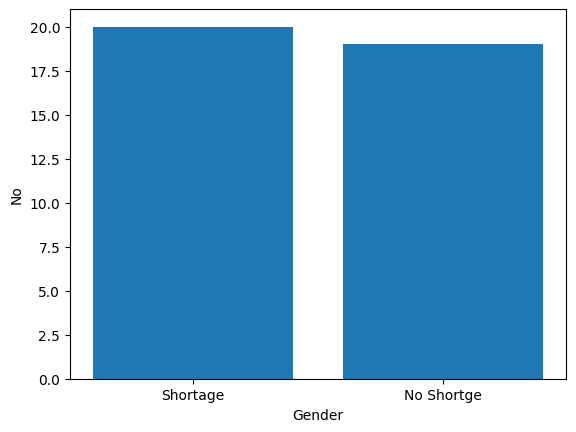

In [46]:
# plt.bar(data2.Gender,data2.Age)
data2['Attendance_Group'] = data2['Attendance'].apply(
    lambda x: 'No Shortge' if x >= 85 else 'Shortage')
plt.bar(data2.Attendance_Group,data2.Age)
plt.xlabel("Gender")
plt.ylabel("No")

In [51]:
data2["PerformanceScore"]=(
    0.4*data2["Marks"]+
    0.3*data2["Attendance"]
)
data2

,Student_Id,Age,Gender,StudyHour,Attendance,Marks,Result,Attendance_Group,PerformanceScore
0,1,18,female,2.500000,75.000000,55.000000,fail,Shortage,44.500000
1,2,19,male,4.000000,85.000000,69.000000,pass,No Shortge,53.100000
2,3,18,female,3.500000,89.000000,75.000000,pass,No Shortge,56.700000
3,4,20,male,5.000000,79.000000,89.000000,pass,Shortage,59.300000
4,5,18,female,2.500000,75.000000,55.000000,fail,Shortage,44.500000
5,6,19,male,4.000000,85.000000,69.000000,pass,No Shortge,53.100000
6,7,18,female,3.500000,89.000000,75.000000,pass,No Shortge,56.700000
7,8,20,male,5.000000,34.488889,89.000000,pass,Shortage,45.946667
8,9,18,female,2.500000,75.000000,55.000000,fail,Shortage,44.500000
9,10,19,male,4.000000,34.488889,69.000000,pass,Shortage,37.946667


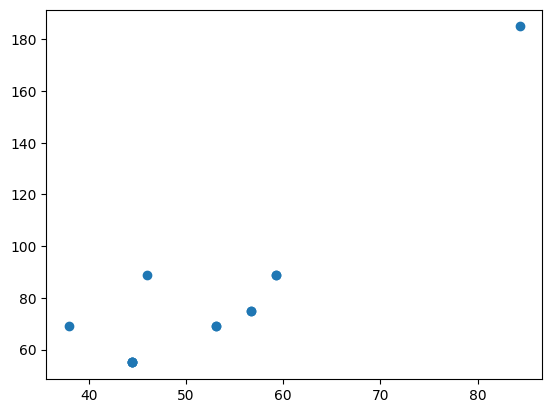

In [54]:
plt.scatter(data2.PerformanceScore,data2.Marks)
plt.show()

In [57]:
x=data2[["StudyHour","Attendance","Marks","PerformanceScore"]]
y=data2["Result"]

In [60]:
x,y

(    StudyHour  Attendance       Marks  PerformanceScore
 0    2.500000   75.000000   55.000000         44.500000
 1    4.000000   85.000000   69.000000         53.100000
 2    3.500000   89.000000   75.000000         56.700000
 3    5.000000   79.000000   89.000000         59.300000
 4    2.500000   75.000000   55.000000         44.500000
 5    4.000000   85.000000   69.000000         53.100000
 6    3.500000   89.000000   75.000000         56.700000
 7    5.000000   34.488889   89.000000         45.946667
 8    2.500000   75.000000   55.000000         44.500000
 9    4.000000   34.488889   69.000000         37.946667
 10   0.968182   34.488889  184.969697         84.334545
 11   5.000000   79.000000   89.000000         59.300000
 12   0.968182   75.000000   55.000000         44.500000,
 0     fail
 1     pass
 2     pass
 3     pass
 4     fail
 5     pass
 6     pass
 7     pass
 8     fail
 9     pass
 10    pass
 11    pass
 12    fail
 Name: Result, dtype: object)

In [73]:
X_train,X_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42
)
X_train,X_test

(    StudyHour  Attendance       Marks  PerformanceScore
 8    2.500000   75.000000   55.000000         44.500000
 5    4.000000   85.000000   69.000000         53.100000
 2    3.500000   89.000000   75.000000         56.700000
 1    4.000000   85.000000   69.000000         53.100000
 12   0.968182   75.000000   55.000000         44.500000
 4    2.500000   75.000000   55.000000         44.500000
 7    5.000000   34.488889   89.000000         45.946667
 10   0.968182   34.488889  184.969697         84.334545
 3    5.000000   79.000000   89.000000         59.300000
 6    3.500000   89.000000   75.000000         56.700000,
     StudyHour  Attendance  Marks  PerformanceScore
 11        5.0   79.000000   89.0         59.300000
 9         4.0   34.488889   69.0         37.946667
 0         2.5   75.000000   55.0         44.500000)

In [74]:
model=DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)
model.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [75]:
y_pred=model.predict(X_test)
y_pred

array(['pass', 'pass', 'fail'], dtype=object)

In [ ]:
result=pd.DataFrame({
    "Actualual"=y_test,
    "Predected"=y_pred
})

In [76]:
acuracy=accuracy_score(y_test,y_pred)
acuracy

1.0

In [79]:
precision = precision_score(y_test, y_pred)
precision


ValueError: pos_label=1 is not a valid label. It should be one of ['fail', 'pass']